<a href="https://colab.research.google.com/github/anitejpadyana/BIS-lab/blob/main/Cuckoo_Search_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Best Fitness: 190.86
Drone Path:
[[ 5.    5.  ]
 [41.27 11.87]
 [16.38 34.12]
 [43.74 47.23]
 [65.88 50.43]
 [96.79 59.38]
 [95.   95.  ]]


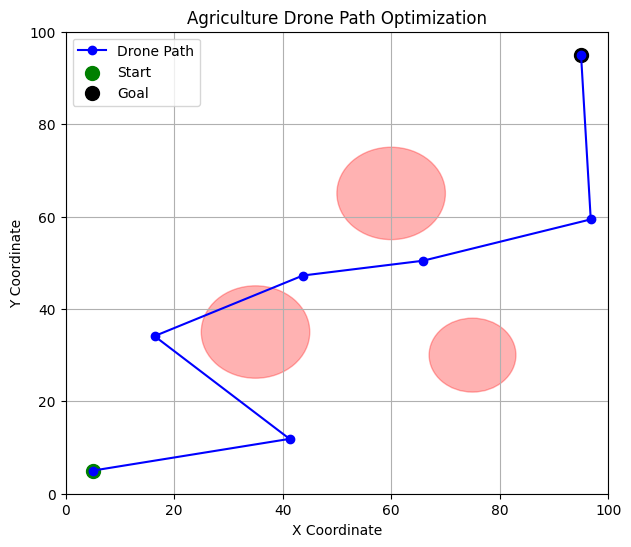

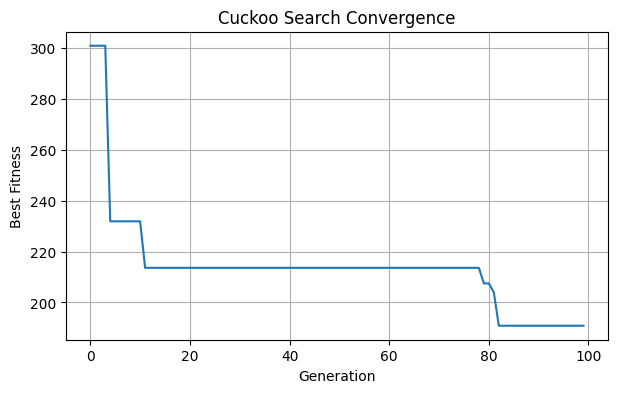

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import math

n = 20
pa = 0.25
alpha = 0.01
beta = 1.5
MaxGen = 100

D = 5
x_min = 0
x_max = 100

start = np.array([5, 5])
goal = np.array([95, 95])

obstacles = [
    (35, 35, 10),
    (60, 65, 10),
    (75, 30, 8)
]

def fitness(x):
    points = x.reshape(D, 2)
    path = np.vstack([start, points, goal])

    distance = np.sum(np.linalg.norm(np.diff(path, axis=0), axis=1))
    penalty = 0

    for ox, oy, r in obstacles:
        for px, py in path:
            d = np.sqrt((px - ox)**2 + (py - oy)**2)
            if d < r + 5:
                penalty += 1000 * (r + 5 - d)**2

    return distance + penalty

def LevyFlight(beta):
    sigma = (
        math.gamma(1 + beta) * np.sin(np.pi * beta / 2) /
        (math.gamma((1 + beta) / 2) * beta *
         2 ** ((beta - 1) / 2))
    ) ** (1 / beta)

    u = np.random.normal(0, sigma, D * 2)
    v = np.random.normal(0, 1, D * 2)

    return u / (np.abs(v) ** (1 / beta))

def CuckooSearch():
    nests = np.random.uniform(x_min, x_max, (n, D * 2))
    fit = np.array([fitness(x) for x in nests])

    best_index = np.argmin(fit)
    best = nests[best_index].copy()
    best_fitness = fit[best_index]

    convergence = []

    for t in range(MaxGen):

        for i in range(n):
            step = LevyFlight(beta)

            x_new = nests[i] + alpha * step * (nests[i] - best)
            x_new = np.clip(x_new, x_min, x_max)

            j = np.random.randint(n)

            if j != i and fitness(x_new) < fit[j]:
                nests[j] = x_new
                fit[j] = fitness(x_new)

        for i in range(n):
            if np.random.random() < pa:
                nests[i] = np.random.uniform(x_min, x_max, D * 2)
                fit[i] = fitness(nests[i])

        best_index = np.argmin(fit)

        if fit[best_index] < best_fitness:
            best = nests[best_index].copy()
            best_fitness = fit[best_index]

        convergence.append(best_fitness)

    return best, best_fitness, convergence

best, best_fitness, convergence = CuckooSearch()

best_path = best.reshape(D, 2)
final_path = np.vstack([start, best_path, goal])

print("Best Fitness:", round(best_fitness, 2))
print("Drone Path:")
print(final_path.round(2))

plt.figure(figsize=(7, 6))

for ox, oy, r in obstacles:
    circle = plt.Circle((ox, oy), r, color='red', alpha=0.3)
    plt.gca().add_patch(circle)

plt.plot(final_path[:, 0], final_path[:, 1], 'b-o', label='Drone Path')
plt.scatter(*start, color='green', s=100, label='Start')
plt.scatter(*goal, color='black', s=100, label='Goal')

plt.title("Agriculture Drone Path Optimization")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(convergence)
plt.title("Cuckoo Search Convergence")
plt.xlabel("Generation")
plt.ylabel("Best Fitness")
plt.grid()
plt.show()